# Signal/background classification

This notebook builds a sideband-labelled dataset from the reconstructed B-candidate mass and trains a Random Forest classifier to separate signal-like candidates from background-like candidates.


## Setup


In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Keep the matplotlib font cache inside the project so notebook runs stay quiet
# even when the default cache directory is not writable.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "B2HHH_MagnetDown.root"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

DATA_PATH

PosixPath('/Users/yanisidir/Projects/lhcb-b2hhh-analysis/data/raw/B2HHH_MagnetDown.root')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from src.reconstruction.invariant_mass import compute_b_mass
from src.ml.signal_background import (
    DEFAULT_FEATURES,
    MassWindows,
    build_signal_background_dataset,
    train_random_forest,
    compute_roc_curve,
)
from src.plotting.mass_plots import plot_mass_distribution, set_hep_style

set_hep_style()


## Load ROOT data

The ROOT ntuple is read with `uproot`, which makes the analysis portable in a pure Python environment while preserving the columnar structure of the original `DecayTree`.


In [3]:
BRANCHES = [
    "H1_PX", "H1_PY", "H1_PZ",
    "H2_PX", "H2_PY", "H2_PZ",
    "H3_PX", "H3_PY", "H3_PZ",
    "H1_Charge", "H2_Charge", "H3_Charge",
    "H1_ProbK", "H2_ProbK", "H3_ProbK",
    "H1_ProbPi", "H2_ProbPi", "H3_ProbPi",
    "B_VertexChi2", "B_FlightDistance",
]

with uproot.open(DATA_PATH) as root_file:
    tree = root_file["DecayTree"]
    df = tree.arrays(BRANCHES, library="pd")

print(f"Loaded candidates: {len(df):,}")
df.head()


Loaded candidates: 5,135,823


,H1_PX,H1_PY,H1_PZ,H2_PX,H2_PY,H2_PZ,H3_PX,H3_PY,H3_PZ,H1_Charge,H2_Charge,H3_Charge,H1_ProbK,H2_ProbK,H3_ProbK,H1_ProbPi,H2_ProbPi,H3_ProbPi,B_VertexChi2,B_FlightDistance
0,375.284205,831.308481,51820.233718,708.073133,-1098.156476,17678.307346,-208.210960,-2586.359121,105848.271681,-1,1,1,0.038616,0.307541,0.193004,0.888755,0.095760,0.138845,1.497280,25.301004
1,-4985.130785,5853.750057,326157.454706,144.300886,85.205300,5324.123346,-175.018535,1325.178792,87681.561846,-1,1,1,0.073556,0.048407,0.080397,0.039064,0.137437,0.758603,1.383338,94.690700
2,-1265.456544,2330.050788,90762.658032,-739.506324,-1036.736792,17885.000646,-1383.996490,-71.081104,85574.929582,1,-1,-1,0.030095,0.000798,0.750751,0.636693,0.986191,0.399602,5.187101,8.284490
3,-720.797259,3413.790588,86793.058768,-381.169232,1081.069786,20276.393591,398.775944,-1134.914464,14653.316611,-1,1,1,0.211414,0.030331,0.005698,0.350969,0.963767,0.964705,7.129099,5.590769
4,397.754571,1791.373059,40040.364159,1841.069628,-794.103213,11610.344506,477.148467,2113.439057,24462.076980,-1,1,1,0.005697,0.012994,0.002979,0.933102,0.886534,0.918983,10.988701,3.013242


## Invariant mass reconstruction

The same B-mass reconstruction as in the exploratory notebook is applied here to keep the classification notebook fully reproducible.


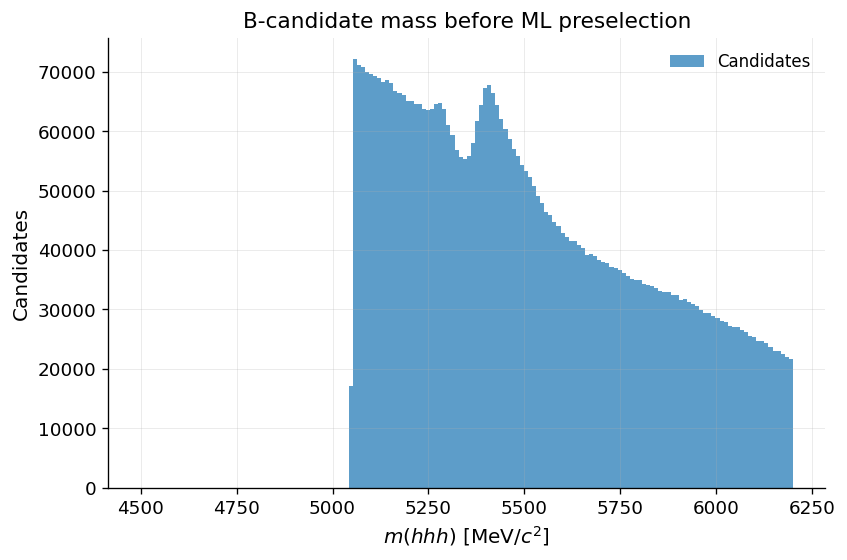

In [4]:
df["B_mass"] = compute_b_mass(df)

fig, ax = plot_mass_distribution(
    df["B_mass"],
    bins=160,
    mass_range=(4500, 6200),
    title="B-candidate mass before ML preselection",
)
plt.show()


## Event selection

The classifier is trained after the same basic quality and kaon-PID preselection used in the mass reconstruction study.


In [5]:
selection_mask = (
    (df["B_VertexChi2"] < 5)
    & (df["B_FlightDistance"] > 20)
    & (df["H1_ProbK"] > 0.5)
    & (df["H2_ProbK"] > 0.5)
    & (df["H3_ProbK"] > 0.5)
)

df_sel = df.loc[selection_mask].copy()
print(f"Candidates after preselection: {len(df_sel):,}")


Candidates after preselection: 1,645


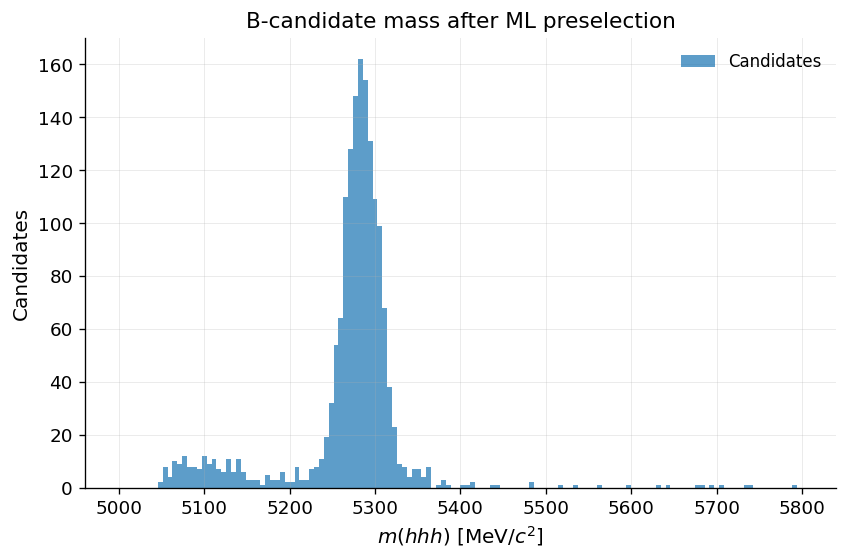

In [6]:
fig, ax = plot_mass_distribution(
    df_sel["B_mass"],
    bins=140,
    mass_range=(5000, 5800),
    title="B-candidate mass after ML preselection",
    output_path=FIGURES_DIR / "B_mass_after_cuts.png",
)
plt.show()


## Signal and sideband regions

A central mass window defines signal-like candidates. Two sidebands define background-like candidates. These labels are useful for training a demonstration classifier, while a precision measurement would account for residual signal leakage and sideband composition.


In [7]:
windows = MassWindows(
    signal=(5270, 5290),
    low_sideband=(5200, 5250),
    high_sideband=(5310, 5350),
)

ml_df = build_signal_background_dataset(df_sel, windows=windows, features=DEFAULT_FEATURES)
print(ml_df["label"].value_counts().rename({1: "signal", 0: "background"}))
ml_df.head()


label
signal        528
background    227
Name: count, dtype: int64


,B_VertexChi2,B_FlightDistance,H1_ProbK,H2_ProbK,H3_ProbK,H1_ProbPi,H2_ProbPi,H3_ProbPi,B_mass,label
0,1.044176,53.008846,0.922096,0.950725,0.921754,0.059316,0.254305,0.092939,5278.782080,1
1,1.234878,25.028023,0.803463,0.769137,0.964152,0.094286,0.038924,0.132662,5280.889118,1
2,2.498335,20.598031,0.926795,0.917369,0.546279,0.038849,0.099470,0.027094,5274.128709,1
3,1.276746,29.455468,0.969167,0.957508,0.924203,0.166821,0.138418,0.061631,5289.354125,1
4,3.702016,28.904012,0.709261,0.750993,0.928394,0.043236,0.039253,0.438700,5283.651674,1


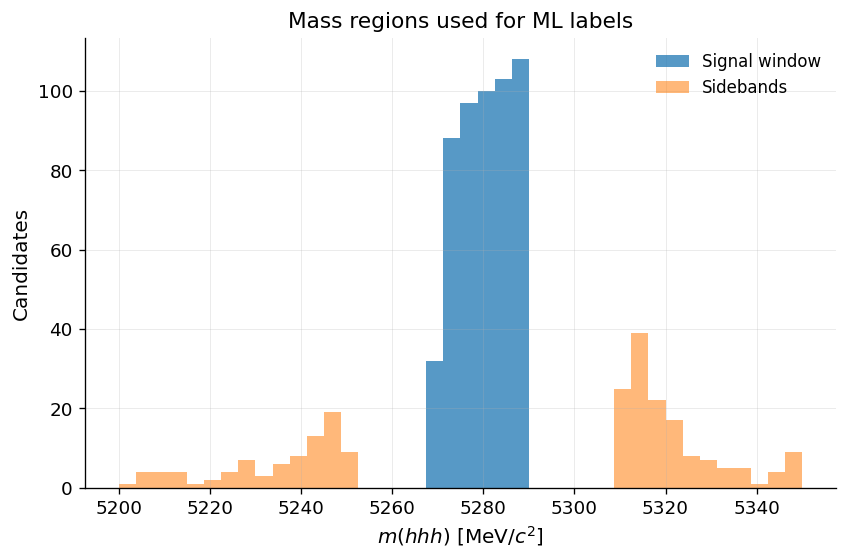

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.hist(
    ml_df.loc[ml_df["label"] == 1, "B_mass"],
    bins=40,
    range=(5200, 5350),
    alpha=0.75,
    label="Signal window",
)
ax.hist(
    ml_df.loc[ml_df["label"] == 0, "B_mass"],
    bins=40,
    range=(5200, 5350),
    alpha=0.55,
    label="Sidebands",
)
ax.set_xlabel(r"$m(hhh)$ [MeV/$c^2$]")
ax.set_ylabel("Candidates")
ax.set_title("Mass regions used for ML labels")
ax.legend(frameon=False)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "signal_sidebands.png", dpi=300, bbox_inches="tight")
plt.show()


## Random Forest training

The feature set is restricted to reconstruction-quality and PID observables. The mass itself is kept out of the training features to avoid teaching the classifier the label definition directly.


In [9]:
classifier, x_train, x_test, y_train, y_test = train_random_forest(
    ml_df,
    features=DEFAULT_FEATURES,
    test_size=0.30,
    random_state=42,
)

y_pred = classifier.predict(x_test)
print(classification_report(y_test, y_pred, target_names=["background", "signal"]))


              precision    recall  f1-score   support

  background       0.35      0.25      0.29        68
      signal       0.71      0.80      0.75       159

    accuracy                           0.63       227
   macro avg       0.53      0.52      0.52       227
weighted avg       0.60      0.63      0.61       227



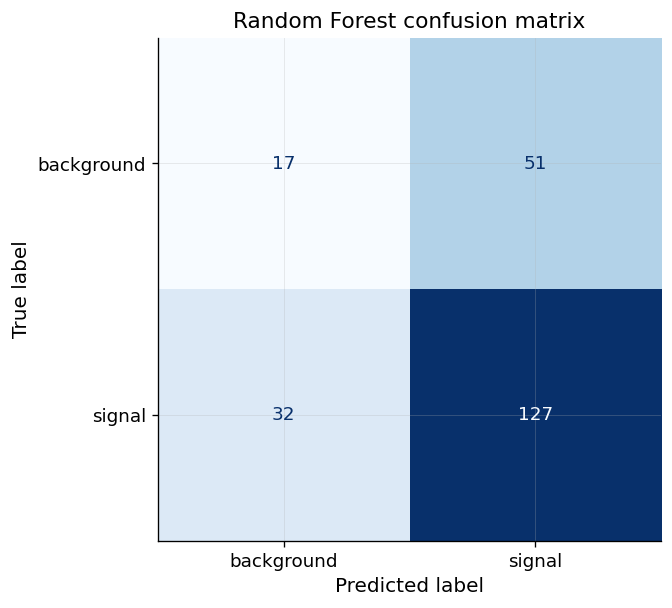

In [10]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["background", "signal"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Random Forest confusion matrix")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrix_signal_background.png", dpi=300, bbox_inches="tight")
plt.show()


## ROC curve


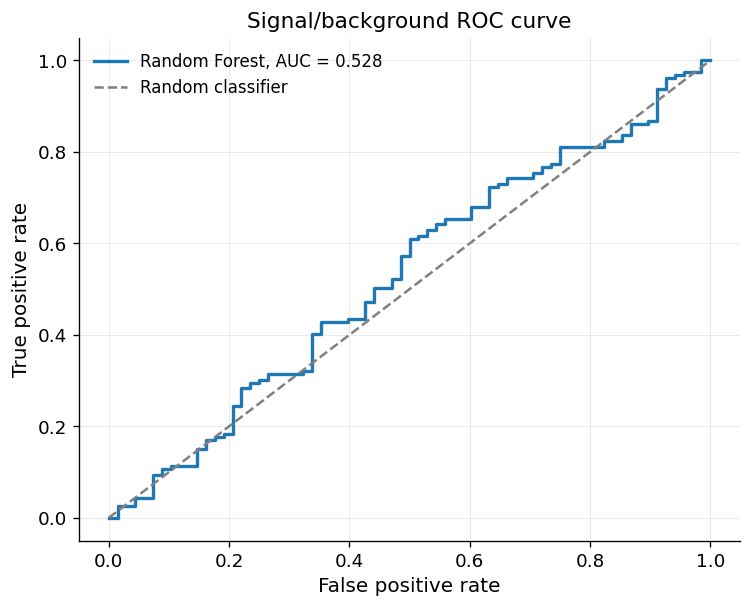

In [11]:
fpr, tpr, thresholds, roc_auc = compute_roc_curve(classifier, x_test, y_test)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.plot(fpr, tpr, linewidth=2.0, label=f"Random Forest, AUC = {roc_auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Signal/background ROC curve")
ax.legend(frameon=False)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "roc_signal_background.png", dpi=300, bbox_inches="tight")
plt.show()


## Feature importance


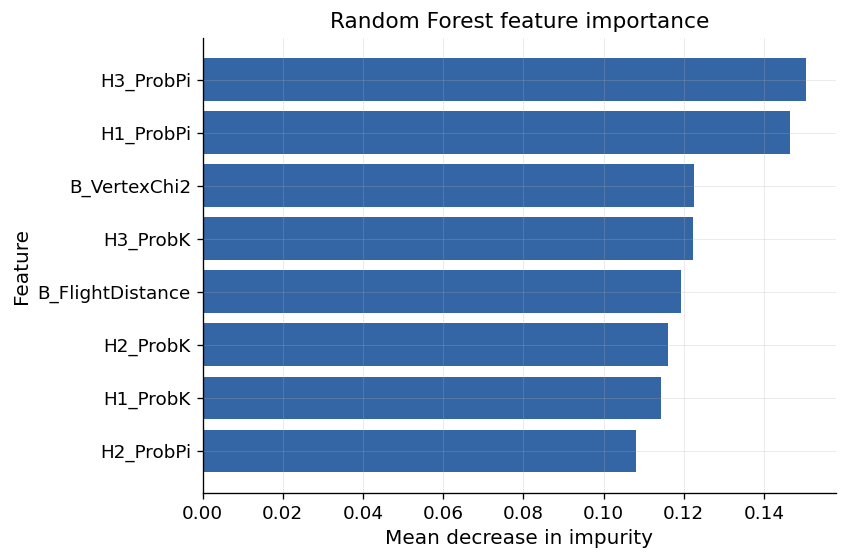

,feature,importance
7,H3_ProbPi,0.150549
5,H1_ProbPi,0.146605
0,B_VertexChi2,0.122524
4,H3_ProbK,0.122327
1,B_FlightDistance,0.119278
3,H2_ProbK,0.116198
2,H1_ProbK,0.114405
6,H2_ProbPi,0.108115


In [12]:
importance_df = (
    pd.DataFrame({"feature": DEFAULT_FEATURES, "importance": classifier.feature_importances_})
    .sort_values("importance", ascending=True)
)

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.barh(importance_df["feature"], importance_df["importance"], color="#3465a4")
ax.set_xlabel("Mean decrease in impurity")
ax.set_ylabel("Feature")
ax.set_title("Random Forest feature importance")
ax.grid(True, axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_importance_signal_background.png", dpi=300, bbox_inches="tight")
plt.show()

importance_df.sort_values("importance", ascending=False)


## Conclusions

The sideband-labelled classifier provides a compact benchmark for signal/background separation using PID and reconstruction-quality variables. The ROC curve and feature ranking give quick diagnostics of classification power and identify which observables dominate the separation.
